# Analiza Nierownowagi Klas: Zbior Zbalansowany vs Niezbalansowany

Ten notebook porownuje zachowanie modelu dla: oryginalnego zbioru niezbalansowanego, niedoprobkowania, nadprobkowania oraz syntetycznego nadprobkowania (SMOTE).


## Metodologia

1. Podziel dane ze stratyfikacja.
2. Pozostaw zbior testowy bez zmian (oryginalny rozklad klas).
3. Zbalansuj tylko dane treningowe.
4. Trenuj ten sam klasyfikator dla kazdego wariantu.
5. Porownaj PR-AUC, F1 klasy mniejszosciowej, Czulosc klasy mniejszosciowej, Zrownowazona trafnosc i macierz pomylek.


In [1]:
from pathlib import Path
import os
import sys
import importlib

start_dir = Path.cwd().resolve()
backend_root = None
for candidate in (start_dir, *start_dir.parents):
    if (candidate / 'utils').is_dir() and (candidate / 'notebooks').is_dir():
        backend_root = candidate
        break
    nested_backend = candidate / 'backend'
    if (nested_backend / 'utils').is_dir() and (nested_backend / 'notebooks').is_dir():
        backend_root = nested_backend
        break

if backend_root is None:
    raise RuntimeError(
        f'Cannot locate backend root from Jupyter working directory: {start_dir}'
    )

notebooks_dir = backend_root / 'notebooks'
os.chdir(notebooks_dir)
if str(backend_root) not in sys.path:
    sys.path.insert(0, str(backend_root))

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    f1_score,
    recall_score,
    balanced_accuracy_score,
    confusion_matrix
)

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE
if 'utils.notebook_plot_style' in sys.modules:
    importlib.reload(sys.modules['utils.notebook_plot_style'])

from utils.notebook_plot_style import (
    save_dataset_figure,
)
from utils.split_dataset_loader import (
    build_controlled_imbalance_frame,
    build_stratified_frames,
    feature_columns,
    load_split_frames,
)






In [2]:
CORPUS_NAME = 'url_corpus'
TARGET_COL = 'phishing'
RANDOM_STATE = 42
ORIGINAL_IMBALANCE_RATIO = 58000 / 30647

if CORPUS_NAME == 'original':
    raw_df = pd.read_csv(backend_root / 'data' / 'dataset_full.csv')
    frames = build_stratified_frames(
        raw_df, validation_size=0.0, test_size=0.2, random_state=RANDOM_STATE
    )
    experiment_train_df = frames['train']
    imbalance_origin = 'naturalny rozkład oryginalnego korpusu'
    plots_root = backend_root.parent / 'results' / 'url_corpus' / 'imbalance_research' / 'plots'
else:
    split_dir = backend_root / 'data' / 'url_corpus' / 'quality_v4_repaired_features'
    frames = load_split_frames(split_dir, 'dataset_full')
    experiment_train_df = build_controlled_imbalance_frame(
        frames['train'],
        majority_label=0,
        majority_to_minority_ratio=ORIGINAL_IMBALANCE_RATIO,
        random_state=RANDOM_STATE,
    )
    imbalance_origin = 'kontrolowany rozkład odpowiadający oryginalnemu korpusowi'
    plots_root = backend_root.parent / 'results' / 'url_corpus' / 'imbalance_research' / 'plots'

test_df = frames['test']
FEATURE_COLUMNS = feature_columns(experiment_train_df)
missing_test_features = set(FEATURE_COLUMNS) - set(test_df.columns)
if missing_test_features:
    raise ValueError(f'Brak cech w zbiorze testowym: {sorted(missing_test_features)}')

X_train = experiment_train_df[FEATURE_COLUMNS]
y_train = experiment_train_df[TARGET_COL]
X_test = test_df[FEATURE_COLUMNS]
y_test = test_df[TARGET_COL]
y = y_train

class_counts = y_train.value_counts().sort_index()
imbalance_ratio = class_counts.max() / class_counts.min()
print(f'Źródło niezbalansowania: {imbalance_origin}')
print(f'Liczba cech modelowych: {len(FEATURE_COLUMNS)}')
print('Rozkład klas treningowych:')
print(class_counts)
print(f'Współczynnik niezbalansowania (major/minor): {imbalance_ratio:.3f}')
print(f'Niezmieniony zbiór testowy: {X_test.shape}')


Źródło niezbalansowania: kontrolowany rozkład odpowiadający oryginalnemu korpusowi
Liczba cech modelowych: 110
Rozkład klas treningowych:
phishing
0    54380
1    28734
Name: count, dtype: int64
Współczynnik niezbalansowania (major/minor): 1.893
Niezmieniony zbiór testowy: (21000, 110)


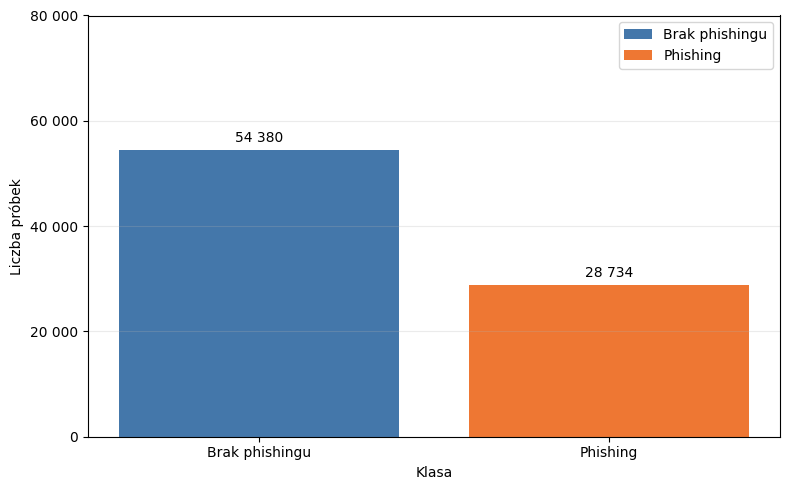

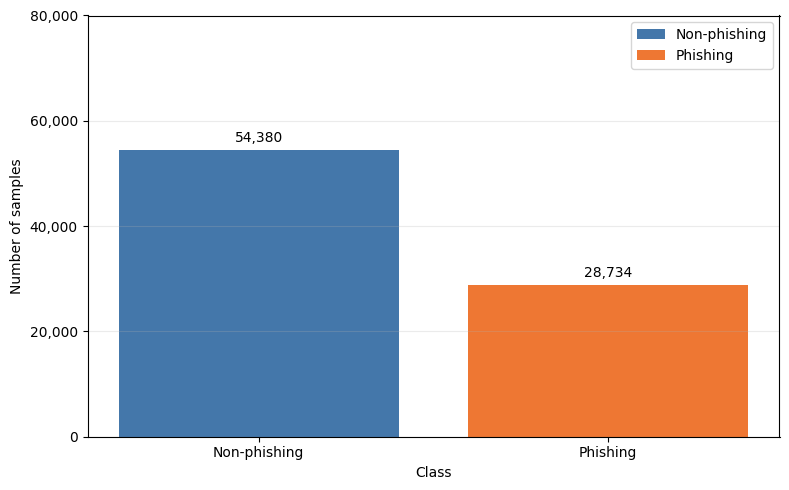

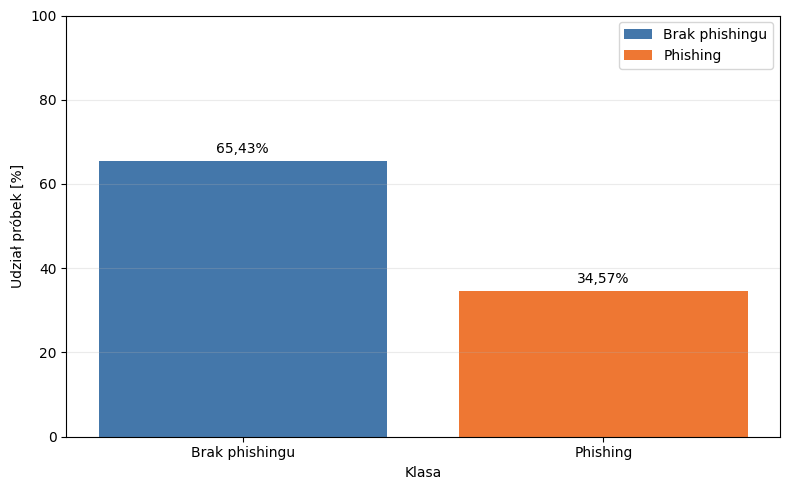

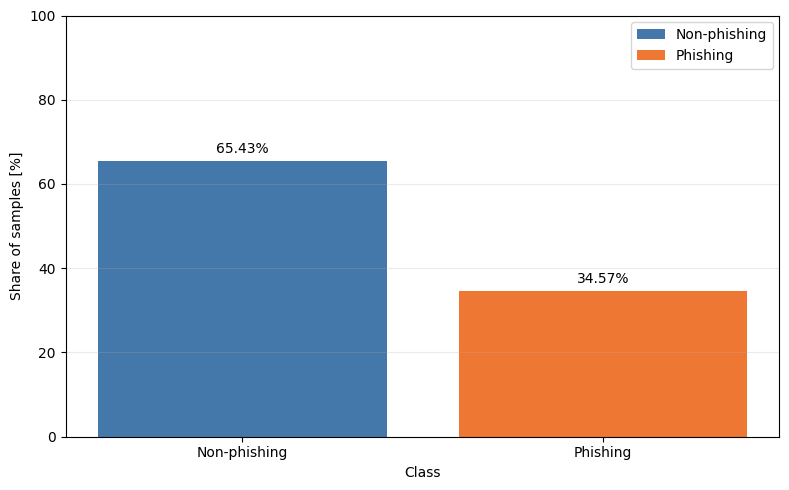

In [3]:
from utils.imbalance_research_plots import (
    plot_class_distribution,
    remove_legacy_imbalance_figures,
)

class_labels = ['Brak phishingu', 'Phishing']
class_counts = y_train.value_counts().reindex([0, 1], fill_value=0)
class_percentages = class_counts.div(class_counts.sum()).mul(100)
remove_legacy_imbalance_figures(plots_root)

distribution_specs = [
    (class_counts.values, False, 'class_distribution_counts.png'),
    (class_percentages.values, True, 'class_distribution_percentages.png'),
]
for values, percentage, filename in distribution_specs:
    figure = plot_class_distribution(
        class_labels, values, percentage=percentage,
    )
    figure.tight_layout()
    save_dataset_figure(figure, plots_root, 'full', filename)
    plt.show()


In [4]:
print('Rozmiar zbioru treningowego:', X_train.shape)
print('Rozmiar niezmienionego zbioru testowego:', X_test.shape)
print('Rozkład klas w zbiorze treningowym:')
print(y_train.value_counts().sort_index())
print('Rozkład klas w zbiorze testowym:')
print(y_test.value_counts().sort_index())


Rozmiar zbioru treningowego: (83114, 110)
Rozmiar niezmienionego zbioru testowego: (21000, 110)
Rozkład klas w zbiorze treningowym:
phishing
0    54380
1    28734
Name: count, dtype: int64
Rozkład klas w zbiorze testowym:
phishing
0    10500
1    10500
Name: count, dtype: int64


## Znaczenie wariantow balansowania

- `bez balansowania`: dane treningowe bez zmian.
- `niedopróbkowanie`: zmniejszenie liczby probek klasy wiekszosciowej.
- `nadpróbkowanie`: zwiekszenie liczby probek klasy mniejszosciowej przez duplikacje.
- `syntetyczne nadpróbkowanie`: syntetyczne nadpróbkowanie (SMOTE), czyli tworzenie nowych probek klasy mniejszosciowej.

Praktyczna interpretacja:

- niedopróbkowanie: szybszy trening, ale ryzyko utraty informacji z klasy wiekszosciowej,
- nadpróbkowanie: brak utraty danych klasy wiekszosciowej, ale ryzyko nadmiernego dopasowania,
- syntetyczne nadpróbkowanie (SMOTE): zwykle lepszy kompromis miedzy recall a precision dla klasy mniejszosciowej.


In [5]:
pipelines = {
    'bez balansowania': SkPipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
    ], memory=None),
    'niedopróbkowanie': ImbPipeline([
        ('sampler', RandomUnderSampler(random_state=RANDOM_STATE)),
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
    ], memory=None),
    'nadpróbkowanie': ImbPipeline([
        ('sampler', RandomOverSampler(random_state=RANDOM_STATE)),
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
    ], memory=None),
    'syntetyczne nadpróbkowanie': ImbPipeline([
        ('sampler', SMOTE(random_state=RANDOM_STATE)),
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
    ], memory=None),
}

minority_label = y.value_counts().idxmin()
print('Wykryta klasa mniejszosciowa:', minority_label)

Wykryta klasa mniejszosciowa: 1


In [6]:
results = []
pr_curves = {}
cms = {}

for variant, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)

    if hasattr(pipe, 'predict_proba') and len(np.unique(y_test)) == 2:
        y_prob = pipe.predict_proba(X_test)[:, 1]
        pr_auc = average_precision_score(y_test, y_prob)
        precision, recall, _ = precision_recall_curve(y_test, y_prob, pos_label=minority_label)
        pr_curves[variant] = (recall, precision)
    else:
        y_prob = None
        pr_auc = np.nan

    f1_min = f1_score(y_test, y_pred, pos_label=minority_label)
    rec_min = recall_score(y_test, y_pred, pos_label=minority_label)
    bacc = balanced_accuracy_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)
    cms[variant] = cm

    results.append({
        'wariant': variant,
        'pr_auc': pr_auc,
        'f1_mniejszosc': f1_min,
        'czulosc_mniejszosci': rec_min,
        'zrownowazona_trafnosc': bacc
    })

results_df = pd.DataFrame(results).sort_values(by='pr_auc', ascending=False)
results_df

,wariant,pr_auc,f1_mniejszosc,czulosc_mniejszosci,zrownowazona_trafnosc
2,nadpróbkowanie,0.929166,0.856341,0.827714,0.861143
3,syntetyczne nadpróbkowanie,0.929003,0.853938,0.822952,0.859238
1,niedopróbkowanie,0.928952,0.855386,0.827810,0.860048
0,bez balansowania,0.928580,0.853713,0.799238,0.863048


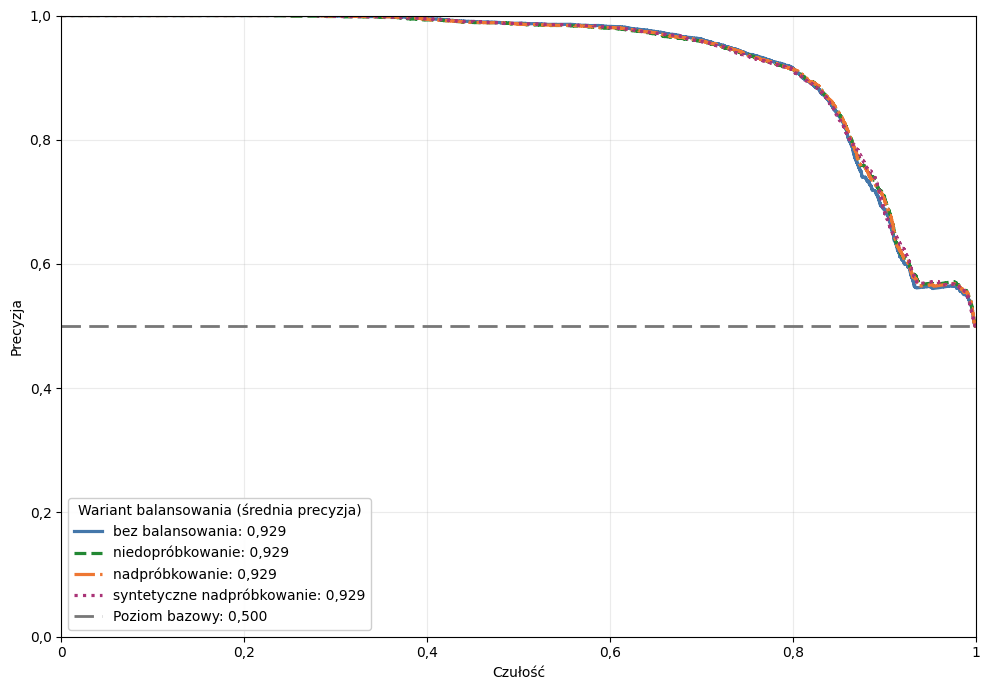

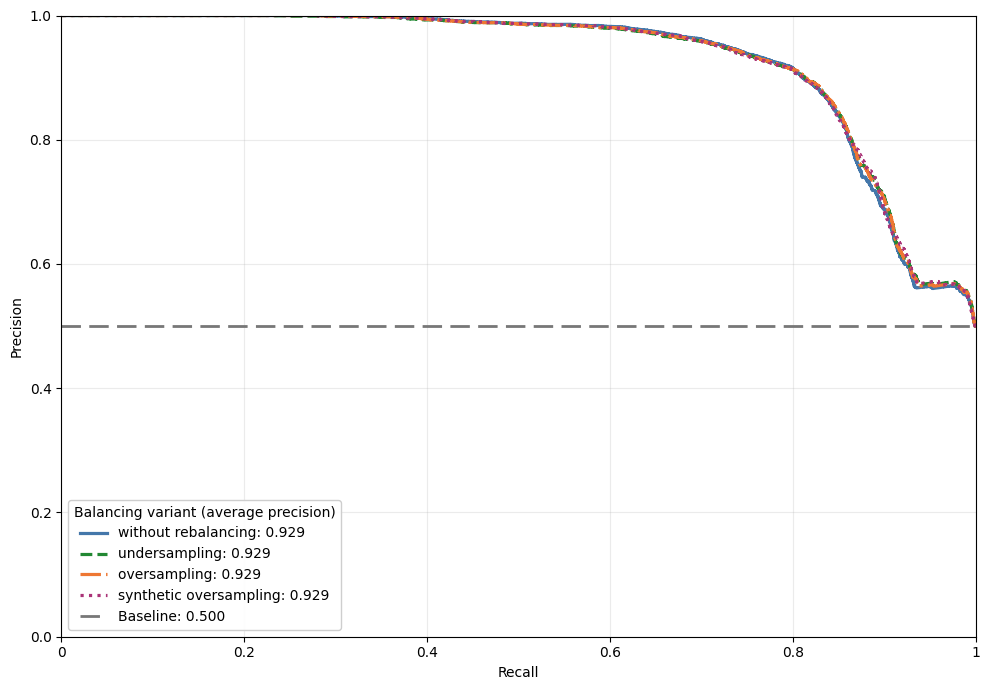

In [7]:
from utils.imbalance_research_plots import (
    plot_precision_recall_curves,
)

if pr_curves:
    average_precision = {
        variant: results_df.loc[
            results_df['wariant'] == variant, 'pr_auc'
        ].iloc[0]
        for variant in pr_curves
    }
    baseline = float((y_test == minority_label).mean())
    figure = plot_precision_recall_curves(
        pr_curves, average_precision, baseline,
    )
    figure.tight_layout()
    save_dataset_figure(
        figure, plots_root, 'full', 'precision_recall_curves.png',
    )
    plt.show()
else:
    print('Krzywe precyzja–czułość są niedostępne dla obecnych etykiet.')


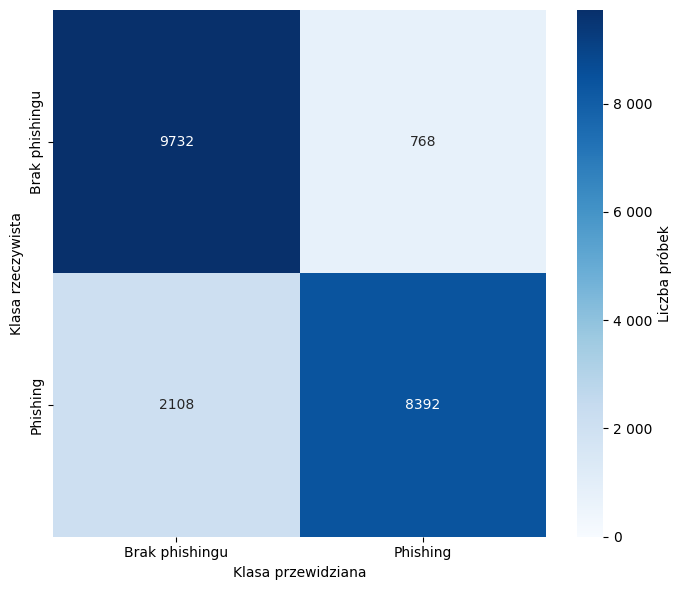

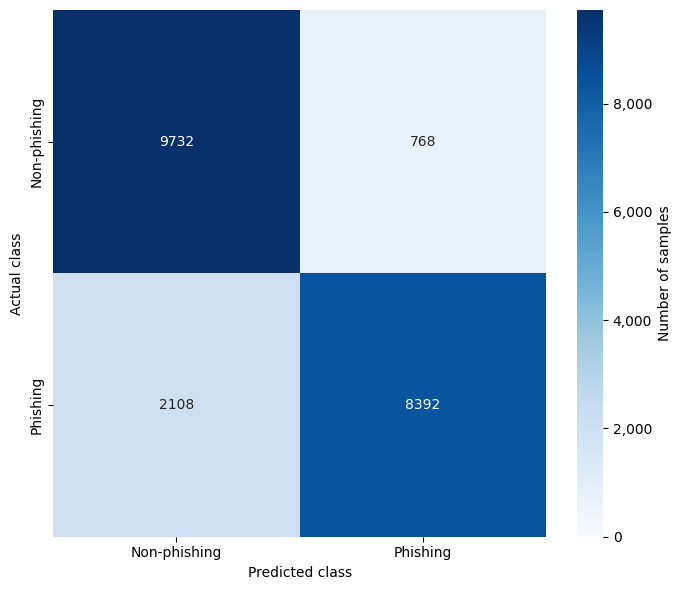

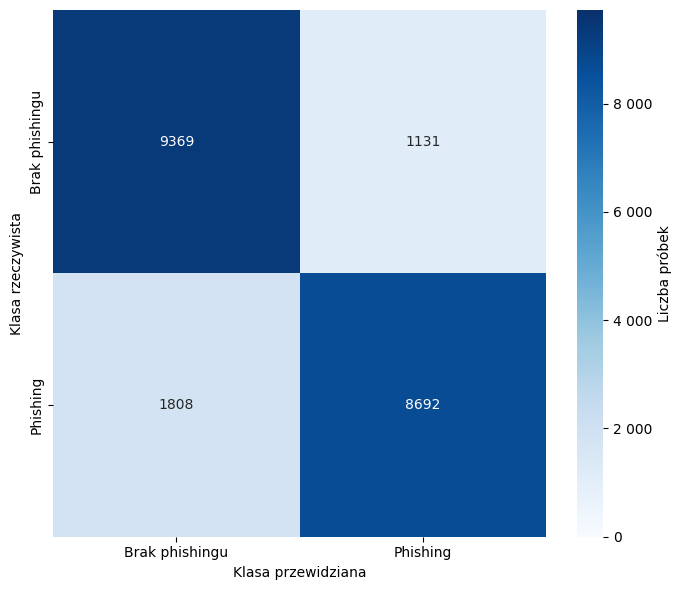

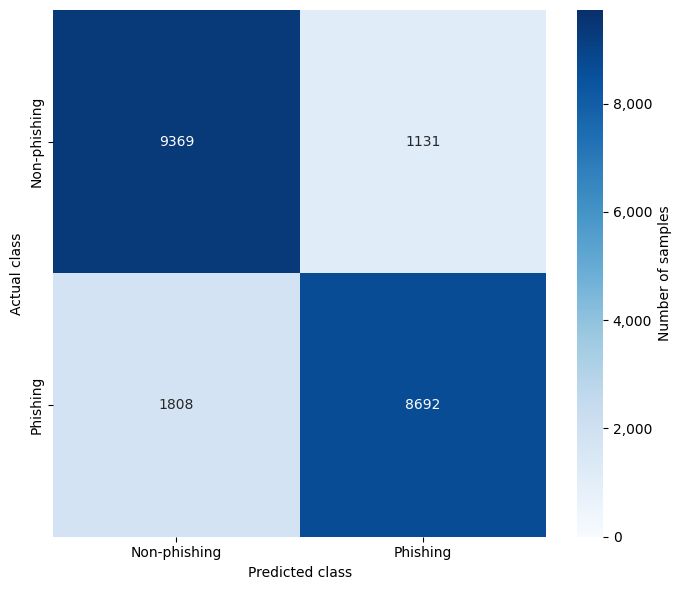

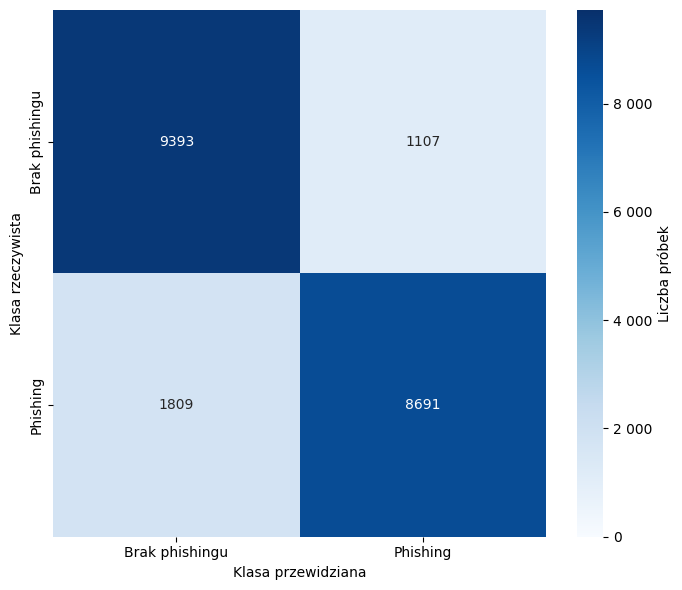

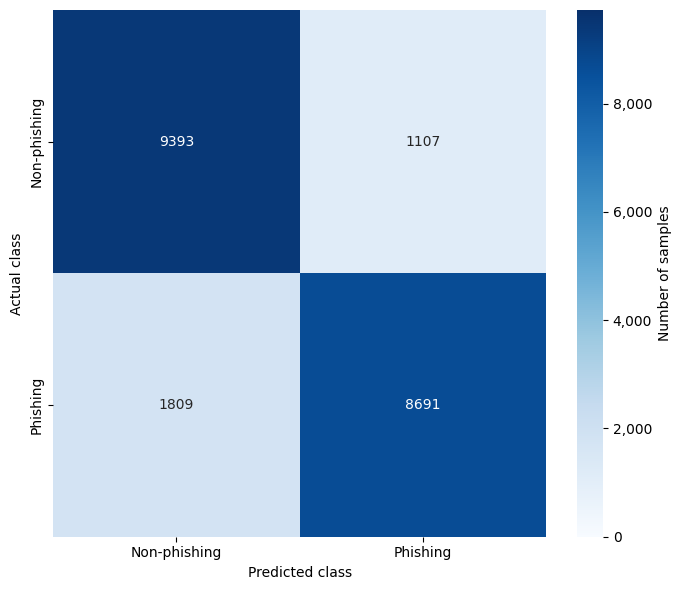

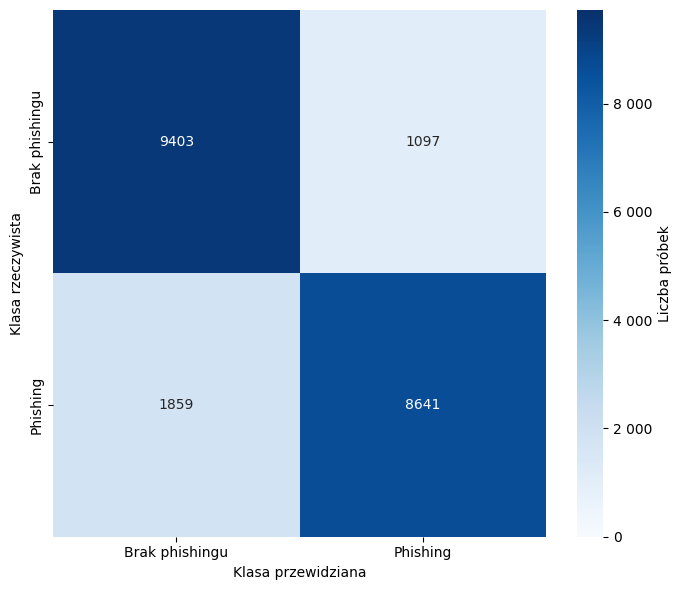

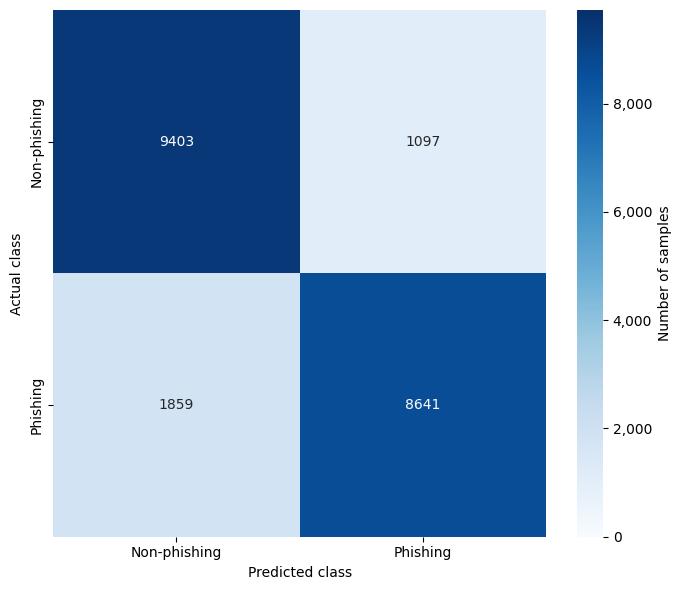

In [8]:
from utils.imbalance_research_plots import (
    plot_imbalance_confusion_matrix,
    shared_confusion_maximum,
)

confusion_maximum = shared_confusion_maximum(cms)
for variant, matrix in cms.items():
    figure = plot_imbalance_confusion_matrix(matrix, confusion_maximum)
    figure.tight_layout()
    safe_variant = variant.replace(' ', '_')
    save_dataset_figure(
        figure, plots_root, 'full',
        f'confusion_matrix_{safe_variant}.png',
    )
    plt.show()


## Wnioski interpretacyjne

- Jesli balansowanie podnosi czulosc klasy mniejszosciowej, ale obniza precyzje, liczba falszywych alarmow rosnie.
- Dla detekcji phishingu priorytetem zwykle jest wysoka czulosc klasy mniejszosciowej (podejscie security-first).
- Model oceniaj lacznie przez PR-AUC i czulosc klasy mniejszosciowej, nie tylko przez trafnosc (accuracy).